# YOLO11s native pipeline at 1280 pixels

**Question.** Can an in-domain pretrained detector, fine-tuned with its own mature
recipe, beat our previous models? The competition baseline is 0.22. Our best Public
scores so far are RT-DETRv2 at 0.24663 and Faster R-CNN at 0.20369. The metric is
standard COCO mAP over IoU 0.50 to 0.95.

**Evidence that shaped the design.**

- Our YOLO11s baseline (validation mAP 0.155, Public 0.14348) did not use the
  Ultralytics trainer. It ran in our shared five-epoch loop with batch 2 and SGD at
  learning rate 0.0025, without mosaic, HSV, affine augmentation or EMA. Its mAP was
  still rising at epoch five, so it measured an unfinished recipe, not the architecture.
- After a 640 pixel resize, 54% of training boxes have $\sqrt{\text{area}} < 16$ px and
  the median is 15 px. With the longer side at 1280 pixels, the median becomes 30 px and
  only 9.8% fall below 16 px, which is two cells of the stride-8 feature map.
- The test frames are smaller (680 to 1920 px wide) than train and validation (1344 to
  3840 px wide). Relative object size is the same, though: the median predicted box width
  is 1.9% to 2.7% of the frame width on test, against 2.2% to 2.3% for annotated boxes.
  We therefore resize by the longer side, which normalizes scale.
- Neighbouring frames are near duplicates. The same tracked object keeps a median IoU
  of 0.90 between consecutive frames, 0.66 at a stride of 4 and 0.44 at a stride of 8.
  Stride 4 keeps 99.4% of the tracks and twice the frames of stride 8.
- Of the training frames, 75% contain ignored regions. Native YOLO training would treat
  their crowds as background, so we paint ignored pixels grey and restore every
  annotated box: 3.5% of boxes touch an ignored region.
- A public YOLO11s trained on VisDrone2019-DET at 1280 px
  ([dronefreak/visdrone-yolo11s](https://huggingface.co/dronefreak/visdrone-yolo11s))
  already detects our eight classes after a channel mapping. We measured it on clips it
  never saw, without any training on our data. On 11 unseen training clips it reaches
  mAP 0.333. On the unseen validation clip it reaches 0.159, where our Faster R-CNN gets
  0.112 and RT-DETRv2 0.100.
- VisDrone-DET contains exact frames of 41 training clips and 6 of the 7 validation
  clips (normalized cross-correlation up to 0.9999), but no test frame (best 0.928, a
  similar scene). It is therefore legitimate external data for the test set. The
  official validation split, however, can no longer measure a DET-initialized model.

**Decision.** One run: the VisDrone-DET YOLO11s with its head mapped to our eight
classes, fine-tuned with the native Ultralytics recipe at 1280 pixels and a low learning
rate. We train on every fourth frame of 57 clips with ignored regions masked. We
validate on a clean fold of six clips that neither VisDrone-DET nor our training
contains. The fold is the unseen validation clip plus five unseen training clips, and
the six contaminated validation clips join training. The number of epochs comes from
throughput measured on the Kaggle GPUs. The final choice among the initial checkpoint,
`best.pt` and `last.pt` uses COCO AP on the clean fold.

**Running on Kaggle.**

1. Attach the competition data and the `hm2-yolo-native` dataset (code bundle with the
   initial checkpoint, plus wheels). Without that dataset the code is downloaded from the Drive `inputs`
   folder.
2. With the default `SHOULD_USE_DRIVE = True`, enable the `HM2_DRIVE_TOKEN` secret. It
   mirrors checkpoints to Drive and allows resuming in a new session. With
   `SHOULD_USE_DRIVE = False`, outputs persist only in `/kaggle/working` of the
   committed version.
3. Select *GPU T4 x2*, set `SHOULD_TRAIN = True` and use *Save Version → Save & Run
   All*. Run All does not train unless that switch is enabled.

**Saved outputs.** The outputs below come from the committed Kaggle run of 8 November
2026 on two T4 GPUs, executed with `SHOULD_TRAIN = True`. Its submission scored 0.34389 on
the Public leaderboard. Section 4 re-renders its object-size histogram from aggregated
bins of the same data, so the notebook stores no raw box values.

## 1. Environment and configuration

The project code comes from an attached dataset that holds `yolo_native_project.zip`
or its extracted contents, or from the same archive in the Drive `inputs` folder. The
first cell installs only the missing packages and keeps Kaggle's CUDA build of PyTorch
and its OpenCV. Ultralytics, its FLOP counter and faster_coco_eval are installed without
dependencies, because everything they import is already in the Kaggle image. Wheels in
the attached dataset allow a run without Internet.

In [1]:
import hashlib
import importlib
import importlib.metadata
import importlib.util
import json
import logging
import os
import platform
import shutil
import subprocess
import sys
import time
import urllib.request
from pathlib import Path
from zipfile import ZipFile

KAGGLE_INPUT = Path("/kaggle/input")
IS_KAGGLE = KAGGLE_INPUT.is_dir()
BUNDLE_NAME = "yolo_native_project.zip"
DRIVE_ROOT = "16wH9gNp13kfa4T039nsiFcZwYOlEJI5Z"
SHOULD_USE_DRIVE = IS_KAGGLE
PINNED_PACKAGES = {
    "ultralytics": "ultralytics==8.3.235",
    "thop": "ultralytics-thop>=2.0.18",
    "faster_coco_eval": "faster-coco-eval>=1.8.0",
}
REQUIREMENTS = {
    "polars": "polars>=1.31",
    "plotly": "plotly>=6",
    "pycocotools": "pycocotools>=2.0.11",
    "googleapiclient": "google-api-python-client",
    "google.oauth2": "google-auth",
}

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
    stream=sys.stdout,
    force=True,
)
LOGGER = logging.getLogger("yolo_native_pipeline")

attached_bundles, wheels = [], None
if IS_KAGGLE:
    attached_bundles = sorted(
        {path for path in KAGGLE_INPUT.rglob(BUNDLE_NAME) if path.is_file()}
        | {path.parent for path in KAGGLE_INPUT.rglob("bundle_manifest.json")}
    )
    if len(attached_bundles) > 1:
        raise ValueError(f"Attach exactly one code bundle: {attached_bundles}")
    if attached_bundles:
        bundle_dataset = KAGGLE_INPUT / attached_bundles[0].relative_to(KAGGLE_INPUT).parts[0]
        wheels = next((path.parent for path in bundle_dataset.rglob("*.whl")), None)
    pinned = [
        package
        for module, package in PINNED_PACKAGES.items()
        if importlib.util.find_spec(module) is None
    ]
    if (
        "ultralytics==8.3.235" not in pinned
        and importlib.metadata.version("ultralytics") != "8.3.235"
    ):
        pinned.append("ultralytics==8.3.235")
    missing = [
        package
        for module, package in REQUIREMENTS.items()
        if importlib.util.find_spec(module) is None
    ]
    installer_prefix = []
    if wheels is not None:
        installer_prefix = [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--no-index",
            "--find-links",
            str(wheels),
        ]
    elif pinned or missing:
        uv_path = shutil.which("uv")
        if uv_path is None:
            installer = Path("/kaggle/working/install_uv.sh")
            urllib.request.urlretrieve("https://astral.sh/uv/install.sh", installer)
            subprocess.run(["sh", str(installer)], check=True)
            uv_path = str(Path.home() / ".local/bin/uv")
        installer_prefix = [uv_path, "pip", "install", "--system", "--python", sys.executable]
    if pinned:
        subprocess.run([*installer_prefix, "--no-deps", *pinned], check=True)
    if missing:
        subprocess.run([*installer_prefix, *missing], check=True)
    LOGGER.info(
        "Installed packages without dependencies: %s; with dependencies: %s", pinned, missing
    )

drive_service = None
if SHOULD_USE_DRIVE:
    from google.oauth2.credentials import Credentials
    from googleapiclient.discovery import build

    UserSecretsClient = importlib.import_module("kaggle_secrets").UserSecretsClient
    token = json.loads(UserSecretsClient().get_secret("HM2_DRIVE_TOKEN"))
    if not token.get("refresh_token"):
        raise ValueError("HM2_DRIVE_TOKEN must contain refreshable Drive credentials.")
    drive_service = build(
        "drive",
        "v3",
        credentials=Credentials.from_authorized_user_info(token),
        cache_discovery=False,
    )
    del token

if IS_KAGGLE:
    REPOSITORY_ROOT = Path("/kaggle/temp/hm2_yolo_code")
    if attached_bundles:
        archive_path = attached_bundles[0]
    elif drive_service is not None:
        from googleapiclient.http import MediaIoBaseDownload

        project = {"id": DRIVE_ROOT}
        for name in ("inputs", BUNDLE_NAME):
            response = (
                drive_service.files()
                .list(
                    q=f"'{project['id']}' in parents and trashed = false",
                    fields="files(id,name,size,md5Checksum)",
                    pageSize=1000,
                )
                .execute(num_retries=3)
            )
            matches = [entry for entry in response["files"] if entry["name"] == name]
            if len(matches) != 1:
                raise FileNotFoundError(f"Expected exactly one {name} in the Drive inputs path.")
            project = matches[0]
        archive_path = Path("/kaggle/temp") / BUNDLE_NAME
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        incoming = archive_path.with_suffix(".incoming")
        with incoming.open("wb") as stream:
            transfer = MediaIoBaseDownload(
                stream,
                drive_service.files().get_media(fileId=project["id"]),
                chunksize=4 * 1024**2,
            )
            has_completed = False
            while not has_completed:
                _, has_completed = transfer.next_chunk(num_retries=3)
        with incoming.open("rb") as stream:
            if hashlib.file_digest(stream, "md5").hexdigest() != project["md5Checksum"]:
                raise ValueError("Code bundle checksum mismatch after the Drive download.")
        incoming.replace(archive_path)
    else:
        raise FileNotFoundError(
            f"Attach a dataset containing {BUNDLE_NAME} or set SHOULD_USE_DRIVE with HM2_DRIVE_TOKEN."
        )
    shutil.rmtree(REPOSITORY_ROOT, ignore_errors=True)
    if archive_path.is_dir():
        shutil.copytree(archive_path, REPOSITORY_ROOT)
    else:
        REPOSITORY_ROOT.mkdir(parents=True)
        with ZipFile(archive_path) as archive:
            for entry in archive.infolist():
                if not (REPOSITORY_ROOT / entry.filename).resolve().is_relative_to(REPOSITORY_ROOT):
                    raise ValueError(f"Unsafe path in the code bundle: {entry.filename}")
            archive.extractall(REPOSITORY_ROOT)
    LOGGER.info("Using project code from %s", archive_path)
else:
    working_directory = Path.cwd().resolve()
    REPOSITORY_ROOT = next(
        directory
        for directory in (working_directory, *working_directory.parents)
        if (directory / "pyproject.toml").is_file() and (directory / "src/hm2").is_dir()
    )
sys.path.insert(0, str(REPOSITORY_ROOT / "src"))

Looking in links: /kaggle/input/datasets/ke1rro/hm2-yolo-native
Processing /kaggle/input/datasets/ke1rro/hm2-yolo-native/ultralytics-8.3.235-py3-none-any.whl
Processing /kaggle/input/datasets/ke1rro/hm2-yolo-native/ultralytics_thop-2.2.5-py3-none-any.whl
Processing /kaggle/input/datasets/ke1rro/hm2-yolo-native/faster_coco_eval-1.8.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl

2026-11-08T14:25:20 [INFO] yolo_native_pipeline: Installed packages without dependencies: ['ultralytics==8.3.235', 'ultralytics-thop>=2.0.18', 'faster-coco-eval>=1.8.0']; with dependencies: []
2026-11-08T14:25:22 [INFO] yolo_native_pipeline: Using project code from /kaggle/input/datasets/ke1rro/hm2-yolo-native/yolo_native_project


In [2]:
import numpy as np
import plotly.express as px
import polars as pl
import torch
import ultralytics
from io import BytesIO
from IPython.display import Image as DisplayImage
from IPython.display import Markdown, display
from PIL import Image
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

from hm2.data import CLASS_NAMES, audit_dataset, find_dataset_root, load_tables
from hm2.experiment_checkpoint import publish_snapshot, write_json
from hm2.faster_rcnn_experiments import find_competition_root
from hm2.visualization import draw_frame, draw_prediction_pair
from hm2.yolo_data import prepare_yolo_dataset, select_dataset_frames, verify_yolo_dataset
from hm2.yolo_pipeline import (
    CheckpointMirror,
    build_yolo_submission,
    classify_ground_truth_outcomes,
    coco_detections,
    evaluate_predictions,
    load_pipeline_settings,
    plan_epochs,
    predict_frames,
    training_arguments,
    write_coco_subset,
)

logging.getLogger("faster_coco_eval").setLevel(logging.WARNING)
ultralytics.settings.update(
    {
        name: False
        for name in (
            "clearml",
            "comet",
            "dvc",
            "hub",
            "mlflow",
            "neptune",
            "raytune",
            "tensorboard",
            "wandb",
        )
    }
)
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)

SHOULD_PREPARE_DATA = True
SHOULD_RUN_SMOKE_TEST = True
SHOULD_TRAIN = False
SHOULD_EVALUATE = True
SHOULD_EXPORT_SUBMISSION = True

SETTINGS = load_pipeline_settings(REPOSITORY_ROOT / "config/yolo11s_native_1280.toml")
BATCH_ID = "yolo11s_native_1280_stride4_seed2026"
EXPERIMENT = "yolo11s_native_1280"
WORK_ROOT = Path("/kaggle/working") if IS_KAGGLE else REPOSITORY_ROOT
TEMP_ROOT = Path("/kaggle/temp") if IS_KAGGLE else REPOSITORY_ROOT / "data"
DATASET_ROOT = TEMP_ROOT / "prepared" / EXPERIMENT
RUN_PROJECT = WORK_ROOT / "runs" / "yolo_native" / BATCH_ID
RUN_DIRECTORY = RUN_PROJECT / EXPERIMENT
MIRROR_DIRECTORY = TEMP_ROOT / "drive_mirror" / BATCH_ID / EXPERIMENT
SUBMISSION_DIRECTORY = WORK_ROOT / "submissions" if IS_KAGGLE else RUN_PROJECT / "submissions"
for directory in (DATASET_ROOT.parent, RUN_PROJECT, SUBMISSION_DIRECTORY):
    directory.mkdir(parents=True, exist_ok=True)
if SHOULD_TRAIN and not torch.cuda.is_available():
    raise RuntimeError("Training requires a CUDA runtime. Select a GPU accelerator.")
device = 0 if torch.cuda.is_available() else "cpu"

LOGGER.info(
    "Switches: prepare=%s, smoke=%s, train=%s, evaluate=%s, export=%s, drive=%s",
    SHOULD_PREPARE_DATA,
    SHOULD_RUN_SMOKE_TEST,
    SHOULD_TRAIN,
    SHOULD_EVALUATE,
    SHOULD_EXPORT_SUBMISSION,
    drive_service is not None,
)
display(
    pl.from_dicts(
        [
            {
                "Python": platform.python_version(),
                "PyTorch": torch.__version__,
                "CUDA": torch.version.cuda,
                "Ultralytics": ultralytics.__version__,
                "GPUs": ", ".join(
                    torch.cuda.get_device_name(index) for index in range(torch.cuda.device_count())
                )
                or "None",
                "CPU cores": os.cpu_count(),
                "Run directory": str(RUN_DIRECTORY),
            }
        ]
    )
)
pl.from_dicts(
    [
        {"Table": table, "Setting": key, "Value": str(value)}
        for table, values in SETTINGS.items()
        for key, value in values.items()
    ]
)

2026-11-08T14:25:22 [INFO] numexpr.utils: NumExpr defaulting to 4 threads.
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
2026-11-08T14:25:38 [INFO] yolo_native_pipeline: Switches: prepare=True, smoke=True, train=True, evaluate=True, export=True, drive=True


Python,PyTorch,CUDA,Ultralytics,GPUs,CPU cores,Run directory
str,str,str,str,str,i64,str
"""3.13.16""","""2.11.0+cu130""","""13.0""","""8.3.235""","""Tesla T4, Tesla T4""",4,"""/kaggle/working/runs/yolo_nati…"


Table,Setting,Value
str,str,str
"""dataset""","""frame_stride""","""4"""
"""dataset""","""image_size""","""1280"""
"""dataset""","""jpeg_quality""","""95"""
"""dataset""","""should_mask_ignored""","""True"""
"""dataset""","""ignore_fill""","""114"""
"""dataset""","""validation_clips""","""['uav0000268_05773_v', 'uav000…"
"""dataset""","""expected_train_frames""","""5966"""
"""dataset""","""expected_train_clips""","""57"""
"""dataset""","""expected_validation_frames""","""3269"""


## 2. Dataset discovery and integrity checks

We rebuild the metadata tables from the original COCO files in this session, so no
cached metadata is required. The audit checks identifiers, image files, label files,
coordinate ranges and the separation of train and validation clips.

In [3]:
SOURCE_ROOT = (
    find_competition_root(KAGGLE_INPUT)
    if IS_KAGGLE
    else find_dataset_root(REPOSITORY_ROOT / "data")
)
if SOURCE_ROOT is None:
    raise FileNotFoundError("Attach the competition data on Kaggle or extract it under data/.")
frames, objects, ignored = load_tables(SOURCE_ROOT)
integrity = audit_dataset(SOURCE_ROOT, frames, objects, ignored)
failed = integrity.filter(~pl.col("is_pass") & (pl.col("check") != "Missing sample submission"))
if not failed.is_empty():
    raise ValueError(f"Dataset integrity checks failed:\n{failed}")
test_frames = pl.read_csv(SOURCE_ROOT / "test_images.csv", schema_overrides={"image_id": pl.String})
if test_frames.height != SETTINGS["dataset"]["expected_test_frames"]:
    raise ValueError("test_images.csv does not list the expected number of test frames.")
display(
    Markdown(
        f"Competition data: `{SOURCE_ROOT}`. The official sample submission is "
        f"{'present' if (SOURCE_ROOT / 'sample_submission.csv').is_file() else 'absent'}; "
        "submissions are validated against `test_images.csv`."
    )
)
integrity

2026-11-08T14:25:39 [INFO] hm2.data: Reading train COCO metadata
2026-11-08T14:25:58 [INFO] hm2.data: Reading val COCO metadata


Competition data: `/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026`. The official sample submission is absent; submissions are validated against `test_images.csv`.

check,count,is_pass
str,i64,bool
"""Duplicate image keys""",0,true
"""Duplicate split image IDs""",0,true
"""Duplicate annotation IDs""",0,true
"""Annotations with unknown image…",0,true
"""Missing image files""",0,true
"""Images absent from metadata""",0,true
"""Missing target label files""",0,true
"""Overlapping train and validati…",0,true
"""Missing sample submission""",1,false


## 3. Training-data preparation

Each selected frame is resized so that its longer side is 1280 pixels and written as a
quality-95 JPEG. Ignored regions are painted with the letterbox grey (114) before
resizing, and annotated boxes are copied back afterwards. YOLO label files are copied
unchanged, since normalized coordinates do not change under an aspect-preserving
resize. Clips are assigned whole, so no sequence is shared. Training uses every fourth
frame of the 51 remaining training clips and the six official validation clips that
VisDrone-DET already contains. Validation keeps every frame of the six clean clips in
`validation_clips`, without random augmentation. Their ignored regions are masked the
same way, so the native per-epoch validation does not count crowd detections as false
positives. The final evaluation in Section 9 uses the original frames and the official
crowd annotations instead.

In [4]:
manifest_path = RUN_PROJECT / "dataset_manifest.json"
if SHOULD_PREPARE_DATA:
    dataset_manifest = prepare_yolo_dataset(
        SOURCE_ROOT,
        DATASET_ROOT,
        frames,
        objects,
        ignored,
        SETTINGS["dataset"],
        os.cpu_count() or 4,
    )
    write_json(manifest_path, dataset_manifest)
else:
    dataset_manifest = json.loads(manifest_path.read_text())
dataset_checks = verify_yolo_dataset(
    DATASET_ROOT, frames, objects, SETTINGS["dataset"], dataset_manifest
)
if not dataset_checks["is_pass"].all():
    raise ValueError(
        f"Prepared dataset checks failed:\n{dataset_checks.filter(~pl.col('is_pass'))}"
    )
DATA_YAML = Path(dataset_manifest["data_yaml"])
display(
    pl.from_dicts(
        [{"Split": split, **counts} for split, counts in dataset_manifest["splits"].items()]
    )
)
dataset_checks

2026-11-08T14:26:16 [INFO] hm2.yolo_data: Rendering 9235 frames into /kaggle/temp/prepared/yolo11s_native_1280 with 4 threads
2026-11-08T14:29:21 [INFO] hm2.yolo_data: Prepared dataset in 185.9 s


Split,frames,clips,labels,masked_regions,frames_with_masks
str,i64,i64,i64,i64,i64
"""train""",5966,57,268937,14830,4345
"""val""",3269,6,148975,8782,2204


check,expected,observed,is_pass
str,str,str,bool
"""Selection digest reproduces""","""8d24df2c42a3df04c2fafaba4ee349…","""8d24df2c42a3df04c2fafaba4ee349…",true
"""Train and validation clips are…","""0""","""0""",true
"""train: frames""","""5966""","""5966""",true
"""train: clips""","""57""","""57""",true
"""train: images without labels""","""0""","""0""",true
"""train: labels without images""","""0""","""0""",true
"""train: readable images""","""5966""","""5966""",true
"""train: image long sides""","""[1280]""","""[1280]""",true
"""train: boxes per class match C…","""[85784, 10652, 119539, 11257, …","""[85784, 10652, 119539, 11257, …",true


## 4. Sampling summary and annotation checks

The table compares class counts in the stride-4 training selection and the clean
validation fold. The redundancy table measures how similar consecutive selected frames
are: the median IoU of the same tracked object $s$ frames apart. The effective size is
$\sqrt{wh}$ after resizing the longer side to 1280 pixels.

In [5]:
selection = select_dataset_frames(
    frames, SETTINGS["dataset"]["frame_stride"], SETTINGS["dataset"]["validation_clips"]
)
selected_objects = pl.concat(
    [
        objects.join(selection[split].select("image_key"), on="image_key").with_columns(
            pl.lit(split).alias("selection")
        )
        for split in selection
    ]
)
class_summary = (
    selected_objects.group_by("selection", "class_id", "class_name")
    .len(name="boxes")
    .with_columns((pl.col("boxes") / pl.col("boxes").sum().over("selection")).alias("fraction"))
    .pivot(on="selection", index=["class_id", "class_name"], values=["boxes", "fraction"])
    .sort("class_id")
    .select("class_name", "boxes_train", "boxes_val", "fraction_train", "fraction_val")
)
display(class_summary)

tracks = objects.filter(pl.col("split") == "train").select(
    "clip", "frame_id", "track_id", "x", "y", "width", "height"
)
redundancy = []
for stride in (1, 2, 4, 8, 16):
    pairs = tracks.join(
        tracks.with_columns(pl.col("frame_id") - stride),
        on=["clip", "frame_id", "track_id"],
        suffix="_next",
    )
    overlap_width = (
        pl.min_horizontal(pl.col("x") + pl.col("width"), pl.col("x_next") + pl.col("width_next"))
        - pl.max_horizontal("x", "x_next")
    ).clip(0)
    overlap_height = (
        pl.min_horizontal(pl.col("y") + pl.col("height"), pl.col("y_next") + pl.col("height_next"))
        - pl.max_horizontal("y", "y_next")
    ).clip(0)
    intersection = overlap_width * overlap_height
    iou = intersection / (
        pl.col("width") * pl.col("height")
        + pl.col("width_next") * pl.col("height_next")
        - intersection
    )
    redundancy.append(
        {"Stride": stride, "Median same-object IoU": pairs.select(iou.median()).item()}
    )
display(pl.from_dicts(redundancy))

effective = selected_objects.with_columns(
    (
        (pl.col("width") * pl.col("height")).sqrt()
        * SETTINGS["dataset"]["image_size"]
        / pl.max_horizontal("image_width", "image_height")
    ).alias("effective_size")
)
display(
    effective.group_by("selection").agg(
        pl.col("effective_size").median().alias("Median effective size px"),
        (pl.col("effective_size") < 8).mean().alias("Below 8 px"),
        (pl.col("effective_size") < 16).mean().alias("Below 16 px"),
        (pl.col("effective_size") < 32).mean().alias("Below 32 px"),
    )
)
size_bins = (
    effective.filter(pl.col("effective_size") < 160)
    .with_columns((pl.col("effective_size") // 2 * 2 + 1).alias("size_bin"))
    .group_by("selection", "size_bin")
    .len(name="boxes")
    .with_columns((pl.col("boxes") / pl.col("boxes").sum().over("selection")).alias("fraction"))
    .sort("selection", "size_bin")
)
px.bar(
    size_bins,
    x="size_bin",
    y="fraction",
    color="selection",
    barmode="overlay",
    labels={
        "size_bin": "Effective object size after resize (px, 2 px bins)",
        "fraction": "Fraction of boxes",
        "selection": "Split",
    },
    title="Object sizes seen by the network at 1280 pixels",
)

class_name,boxes_train,boxes_val,fraction_train,fraction_val
str,u32,u32,f64,f64
"""person""",85784,38079,0.318974,0.255607
"""bicycle""",10652,3935,0.039608,0.026414
"""car""",119539,60502,0.444487,0.406122
"""van""",11257,8950,0.041857,0.060077
"""truck""",7167,3299,0.026649,0.022145
"""tricycle""",8536,12924,0.03174,0.086753
"""bus""",2297,790,0.008541,0.005303
"""motor""",23705,20496,0.088143,0.13758


Stride,Median same-object IoU
i64,f64
1,0.896694
2,0.809524
4,0.660596
8,0.439791
16,0.179949


selection,Median effective size px,Below 8 px,Below 16 px,Below 32 px
str,f64,f64,f64,f64
"""train""",30.505938,0.006444,0.095097,0.539271
"""val""",31.189567,0.003913,0.115617,0.517214


We draw labels and ignored regions on prepared training frames: the densest frame, the
frame with the smallest objects, and the frame with the most ignored regions. Masked
areas appear grey under the magenta overlay, and every box should still enclose its
object.

**Densest frame.** `train/uav0000126_00001_v/0000321`, 156 objects, 21 ignored regions.

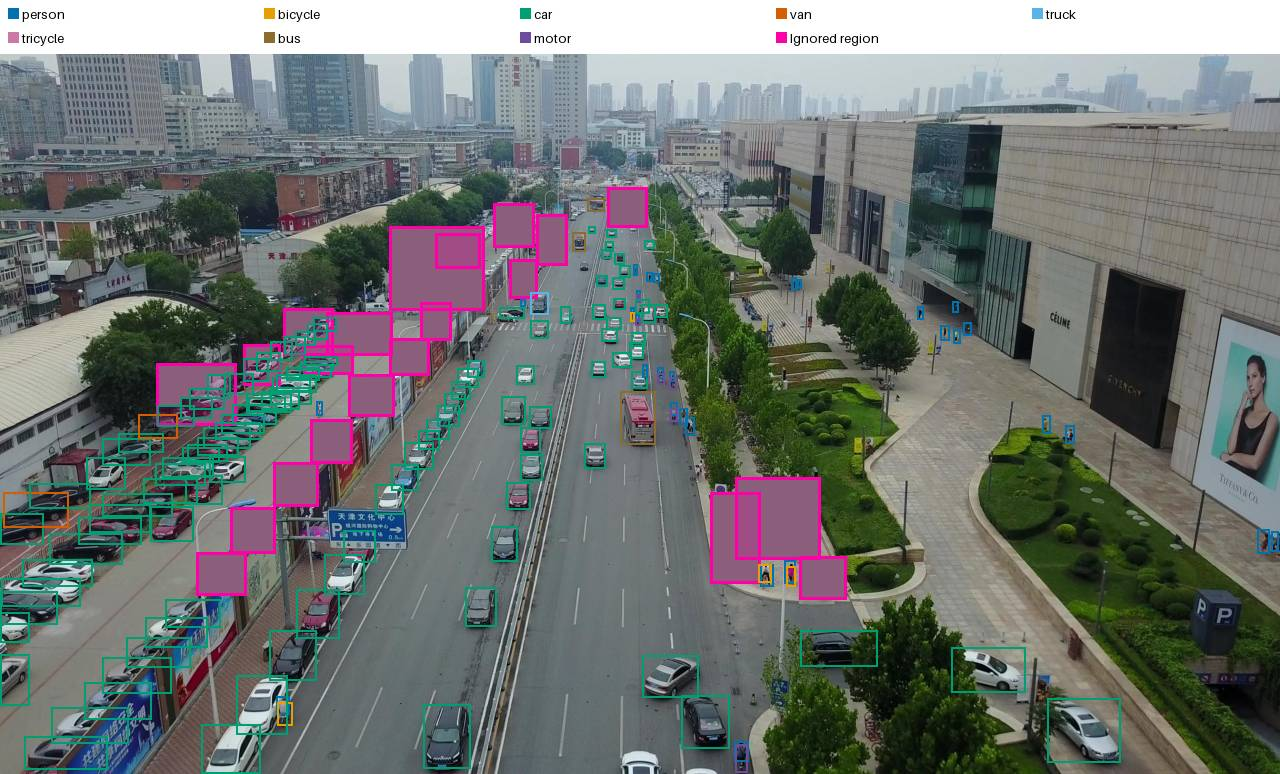

**Smallest objects.** `train/uav0000124_00944_v/0000001`, 120 objects, 2 ignored regions.

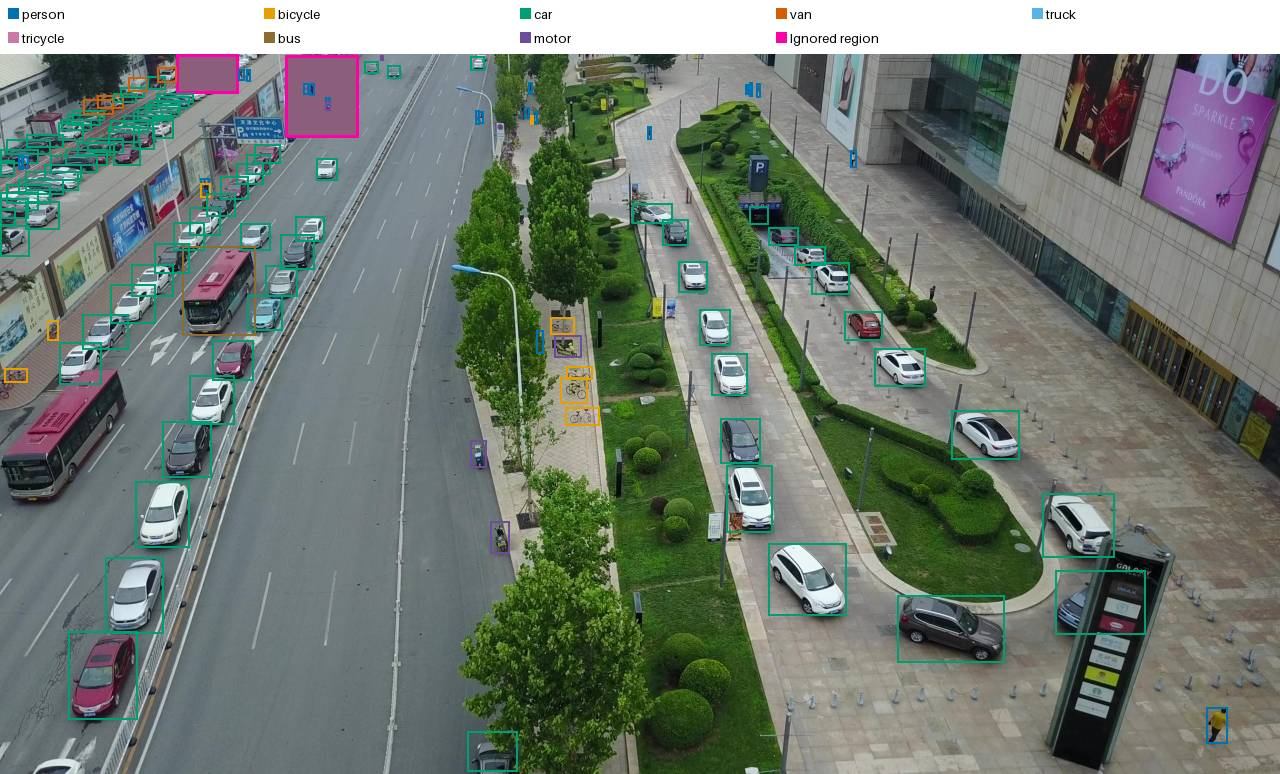

**Most ignored regions.** `train/uav0000126_00001_v/0000301`, 155 objects, 21 ignored regions.

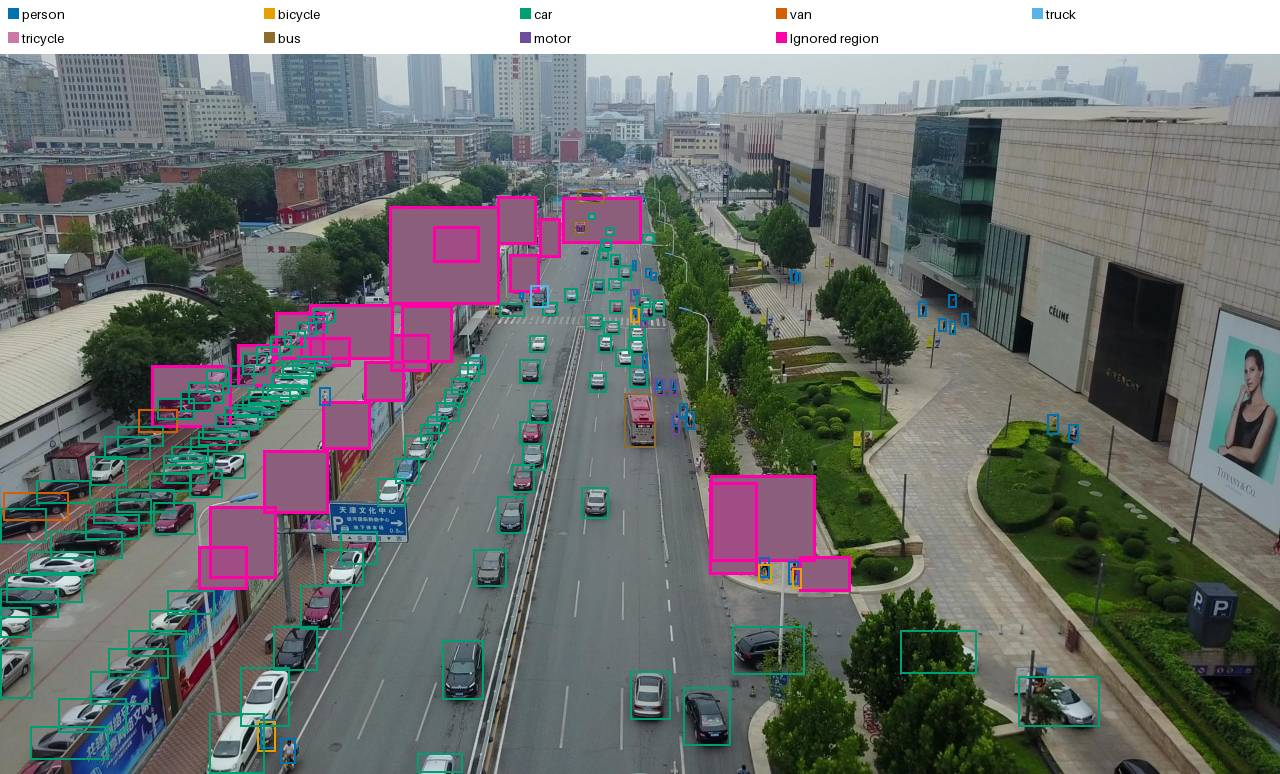

In [6]:
def display_image(image: Image.Image) -> None:
    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=70)
    display(DisplayImage(data=buffer.getvalue()))


train_selection = selection["train"].join(
    objects.group_by("image_key").agg(pl.col("area").min().alias("min_area")),
    on="image_key",
    how="left",
)
examples = {
    "Densest frame": train_selection.sort("target_count", descending=True).row(0, named=True),
    "Smallest objects": train_selection.sort("min_area", nulls_last=True).row(0, named=True),
    "Most ignored regions": train_selection.sort("ignore_count", descending=True).row(
        0, named=True
    ),
}
for title, record in examples.items():
    scale = SETTINGS["dataset"]["image_size"] / max(record["image_width"], record["image_height"])
    scaled = [pl.col(column) * scale for column in ("x", "y", "width", "height")]
    display(
        Markdown(
            f"**{title}.** `{record['image_key']}`, {record['target_count']} objects, "
            f"{record['ignore_count']} ignored regions."
        )
    )
    display_image(
        draw_frame(
            DATASET_ROOT / "images" / "train" / record["clip"] / f"{record['frame']}.jpg",
            objects.filter(pl.col("image_key") == record["image_key"]).with_columns(scaled),
            ignored.filter(pl.col("image_key") == record["image_key"]).with_columns(scaled),
            max_width=1280,
            should_label=False,
        )
    )

## 5. Model initialization

We start from YOLO11s trained on VisDrone2019-DET at 1280 px by the DetectionBench
project (AGPL-3.0, pinned Hugging Face revision; VisDrone data are CC BY-NC-SA 3.0). Its
head has eleven VisDrone classes. `scripts/build_yolo_bundle.py` copies every tensor
and gives each competition class the classification channel of one source class:

- person takes pedestrian;
- tricycle takes tricycle;
- the other six classes map one to one.

The converted network reproduces the source scores for these channels exactly, and
fine-tuning teaches it the merged person and tricycle classes. The conversion
provenance is stored inside the checkpoint.

In [7]:
WEIGHTS = (
    REPOSITORY_ROOT / ("weights" if IS_KAGGLE else "data/weights") / SETTINGS["model"]["model_id"]
)
initial_checkpoint = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
display(
    pl.from_dicts(
        [
            {
                **initial_checkpoint["head_remap"],
                "source_names": str(initial_checkpoint["head_remap"]["source_names"]),
            }
        ]
    )
)
pretrained = YOLO(str(WEIGHTS))
network = pretrained.model
if not isinstance(network, torch.nn.Module):
    raise TypeError("The checkpoint did not load a PyTorch detection model.")
pl.from_dicts(
    [
        {
            "Checkpoint": str(WEIGHTS),
            "Parameters (M)": sum(value.numel() for value in network.parameters()) / 1e6,
            "GFLOPs at 640 px": get_flops(network, 640),
            "GFLOPs at 1280 px": get_flops(network, SETTINGS["dataset"]["image_size"]),
            "Pretrained classes": len(pretrained.names),
        }
    ]
)

source_sha256,source_channels,source_names
str,list[i64],str
"""3134756bf29e761550991c0f1e5d91…","[0, 2, … 9]","""{0: 'pedestrian', 1: 'people',…"


Checkpoint,Parameters (M),GFLOPs at 640 px,GFLOPs at 1280 px,Pretrained classes
str,f64,f64,f64,i64
"""/kaggle/temp/hm2_yolo_code/wei…",9.430888,21.558938,86.23575,8


## 6. Training configuration and throughput check

Every recipe value is passed to the native trainer explicitly:

- **Optimizer.** SGD with momentum 0.937 and weight decay 0.0005, scaled to a nominal
  batch of 64, with EMA weights.
- **Schedule.** The initial model is already converged on VisDrone, with a final
  learning rate of about $6 \cdot 10^{-4}$. We therefore restart gently: lr0 0.002, a
  one-epoch warmup without the default high bias learning rate, and linear decay to
  $0.1 \cdot \text{lr0}$. Ultralytics stops early after 10 epochs without improvement on
  the clean fold.
- **Augmentation.** The source model's own augmentation recipe: HSV jitter, translation
  0.1, scale 0.3, horizontal flip 0.5 and mosaic, which is switched off for the last 5
  epochs. Rotation, shear, perspective and vertical flip stay off, because drone footage
  keeps its perspective orientation.
- **Batch.** 16 images on two T4 GPUs with DDP, 8 per GPU, with AMP.

The epoch budget is deliberately small, at most 30 epochs in 5 hours. Long training on
57 clips could erode the scene diversity learned from VisDrone-DET.

Before full training we train two short epochs on 20% of the frames and time one full
validation. We set the number of epochs to the largest that fits `budget_hours` and
show the plan before training starts.

In [8]:
training = SETTINGS["training"]
requested_gpus = 0 if training["device"] == "cpu" else len(str(training["device"]).split(","))
if SHOULD_TRAIN and torch.cuda.device_count() < requested_gpus:
    raise RuntimeError(
        f"The configuration requests {requested_gpus} GPUs but {torch.cuda.device_count()} are "
        "visible. Select GPU T4 x2 or change device, batch and budget in the configuration."
    )
plan_path = RUN_PROJECT / "training_plan.json"
last_checkpoint = RUN_DIRECTORY / "weights" / "last.pt"

if drive_service is not None:
    from hm2.drive_api import DriveApi, download_current_generation, sync_checkpoint_to_drive_api

    drive_api = DriveApi(drive_service)
    drive_folder = drive_api.folder(
        drive_api.folder(drive_api.folder(DRIVE_ROOT, "batches"), BATCH_ID), EXPERIMENT
    )
    restored = download_current_generation(drive_api, drive_folder, MIRROR_DIRECTORY)
    restore_targets = {
        "last.pt": RUN_DIRECTORY / "weights" / "last.pt",
        "best.pt": RUN_DIRECTORY / "weights" / "best.pt",
        "results.csv": RUN_DIRECTORY / "results.csv",
        "training_plan.json": plan_path,
    }
    if restored and not last_checkpoint.is_file():
        for name, target in restore_targets.items():
            if (MIRROR_DIRECTORY / name).is_file():
                target.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(MIRROR_DIRECTORY / name, target)
    LOGGER.info("Drive generation restored: %s", restored.get("generation", "none"))

checkpoint_epoch = (
    torch.load(last_checkpoint, map_location="cpu", weights_only=False)["epoch"]
    if last_checkpoint.is_file()
    else None
)
is_training_complete = checkpoint_epoch == -1
is_resuming = checkpoint_epoch is not None and checkpoint_epoch >= 0

if SHOULD_TRAIN and SHOULD_RUN_SMOKE_TEST and checkpoint_epoch is None:
    shutil.rmtree(RUN_PROJECT / "smoke", ignore_errors=True)
    smoke_arguments = training_arguments(SETTINGS, DATA_YAML, RUN_PROJECT, "smoke", epochs=2)
    smoke_arguments.update(fraction=training["smoke_fraction"], val=False, plots=False)
    YOLO(str(WEIGHTS)).train(**smoke_arguments)
    smoke_history = pl.read_csv(RUN_PROJECT / "smoke" / "results.csv")
    started = time.monotonic()
    YOLO(str(RUN_PROJECT / "smoke" / "weights" / "last.pt")).val(
        data=str(DATA_YAML),
        imgsz=SETTINGS["dataset"]["image_size"],
        batch=training["batch"],
        device=device,
        half=True,
        plots=False,
        verbose=False,
    )
    validation_seconds = time.monotonic() - started
    smoke_images = round(dataset_manifest["splits"]["train"]["frames"] * training["smoke_fraction"])
    second_epoch_seconds = smoke_history["time"][1] - smoke_history["time"][0] - validation_seconds
    seconds_per_image = max(second_epoch_seconds, smoke_history["time"][0]) / smoke_images
    planned_epochs = plan_epochs(
        seconds_per_image,
        validation_seconds,
        dataset_manifest["splits"]["train"]["frames"],
        training,
    )
    training_plan = {
        "smoke_images": smoke_images,
        "seconds_per_train_image": seconds_per_image,
        "validation_seconds": validation_seconds,
        "planned_epochs": planned_epochs,
        "projected_hours": planned_epochs
        * (
            seconds_per_image * dataset_manifest["splits"]["train"]["frames"]
            + validation_seconds * training["validation_time_margin"]
        )
        / 3600,
        "gpus": [torch.cuda.get_device_name(index) for index in range(torch.cuda.device_count())],
    }
    write_json(plan_path, training_plan)
training_plan = json.loads(plan_path.read_text()) if plan_path.is_file() else {}
if SHOULD_TRAIN and checkpoint_epoch is None and not training_plan:
    raise RuntimeError(
        "Enable SHOULD_RUN_SMOKE_TEST or restore training_plan.json before training."
    )
display(pl.from_dicts([training_plan]) if training_plan else Markdown("No training plan yet."))
pl.from_dicts(
    [
        {"Argument": key, "Value": str(value)}
        for key, value in training_arguments(
            SETTINGS, DATA_YAML, RUN_PROJECT, EXPERIMENT, training_plan.get("planned_epochs", 0)
        ).items()
    ]
)

2026-11-08T14:30:12 [INFO] yolo_native_pipeline: Drive generation restored: none
Ultralytics 8.3.235 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/temp/prepared/yolo11s_native_1280/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.2, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/temp/hm2

smoke_images,seconds_per_train_image,validation_seconds,planned_epochs,projected_hours,gpus
i64,f64,f64,i64,f64,list[str]
1193,0.045704,60.381227,30,2.901231,"[""Tesla T4"", ""Tesla T4""]"


Argument,Value
str,str
"""data""","""/kaggle/temp/prepared/yolo11s_…"
"""imgsz""","""1280"""
"""epochs""","""30"""
"""device""","""0,1"""
"""project""","""/kaggle/working/runs/yolo_nati…"
"""name""","""yolo11s_native_1280"""
"""exist_ok""","""True"""
"""cache""","""False"""
"""rect""","""False"""


The smoke run uses the first 20% of training frames, so its throughput describes those
clips. We take the slower of the two smoke epochs, which keeps the plan conservative.

## 7. Full training

A fresh run starts from the pretrained checkpoint with the planned epochs. A run
interrupted in an earlier session resumes from its own `last.pt`, which carries the
optimizer, EMA, epoch and the original arguments. When Drive is configured, a
background thread publishes `last.pt`, `best.pt` and `results.csv` after every saved
epoch through the verified snapshot transport. Kaggle also keeps `/kaggle/working`
when a committed run finishes.

In [9]:
if SHOULD_TRAIN and not is_training_complete:
    mirror = None
    if drive_service is not None:

        def publish_mirror(directory: Path) -> None:
            shutil.copy2(plan_path, directory / "training_plan.json")
            publish_snapshot(directory)
            sync_checkpoint_to_drive_api(drive_api, directory, drive_folder)

        mirror = CheckpointMirror(RUN_DIRECTORY, MIRROR_DIRECTORY, publish_mirror)
        mirror.start()
    started = time.monotonic()
    try:
        if is_resuming:
            LOGGER.info("Resuming from epoch %d", checkpoint_epoch + 1)
            YOLO(str(last_checkpoint)).train(resume=True)
        else:
            YOLO(str(WEIGHTS)).train(
                **training_arguments(
                    SETTINGS, DATA_YAML, RUN_PROJECT, EXPERIMENT, training_plan["planned_epochs"]
                )
            )
    finally:
        if mirror is not None:
            mirror.stop()
    LOGGER.info("Training session took %.2f h", (time.monotonic() - started) / 3600)
    is_training_complete = (
        torch.load(last_checkpoint, map_location="cpu", weights_only=False)["epoch"] == -1
    )
Markdown(
    f"Training complete: **{is_training_complete}**. Checkpoints: `{RUN_DIRECTORY / 'weights'}`."
)

Ultralytics 8.3.235 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/temp/prepared/yolo11s_native_1280/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/temp/hm2_yolo_code/weights/yolo11s_visdrone_det_8cls.pt, momentum=0.937, mosaic=1.0, mul

Training complete: **True**. Checkpoints: `/kaggle/working/runs/yolo_native/yolo11s_native_1280_stride4_seed2026/yolo11s_native_1280/weights`.

## 8. Training and validation history

These curves come from the native trainer's `results.csv`. Its validation uses the
masked 1280 pixel frames and Ultralytics' own AP computation. Ultralytics selects
`best.pt` by $0.1\,\text{mAP}_{50} + 0.9\,\text{mAP}_{50:95}$.

In [10]:
history_path = RUN_DIRECTORY / "results.csv"
if history_path.is_file():
    history = pl.read_csv(history_path).rename(lambda column: column.strip())
    metric_history = history.select(
        "epoch",
        pl.col("metrics/mAP50-95(B)").alias("mAP50-95"),
        pl.col("metrics/mAP50(B)").alias("mAP50"),
        pl.col("metrics/recall(B)").alias("Recall"),
    ).unpivot(index="epoch", variable_name="Metric", value_name="Value")
    display(
        px.line(
            metric_history,
            x="epoch",
            y="Value",
            color="Metric",
            labels={"epoch": "Epoch", "Value": "Native validation value"},
            title="Native per-epoch validation on masked 1280 pixel frames",
        )
    )
    loss_history = history.select(
        "epoch",
        "train/box_loss",
        "train/cls_loss",
        "train/dfl_loss",
        "val/box_loss",
        "val/cls_loss",
    ).unpivot(index="epoch", variable_name="Loss", value_name="Value")
    display(
        px.line(
            loss_history,
            x="epoch",
            y="Value",
            color="Loss",
            labels={"epoch": "Epoch", "Value": "Loss value"},
            title="Training and validation losses",
        )
    )
    display(history.sort("metrics/mAP50-95(B)", descending=True).head(3))
else:
    display(Markdown("No training history in this session."))

epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,292.982,1.54465,0.87685,1.09371,0.67759,0.61503,0.63242,0.38197,1.51152,1.10124,1.05137,0.001995,0.001995,0.001995
2,574.987,1.43348,0.78783,1.05214,0.66674,0.58828,0.61872,0.37527,1.50245,1.11808,1.05316,0.00194,0.00194,0.00194
8,2269.69,1.29556,0.66208,1.00666,0.67047,0.56641,0.59899,0.36113,1.51813,1.16723,1.06048,0.00158,0.00158,0.00158


## 9. Checkpoint selection on the clean validation fold

This is our closest local proxy for the competition metric, standard COCO mAP. We run
inference on the original, unmasked frames of the clean fold. We evaluate COCO bbox AP
over IoU 0.50 to 0.95 with category-specific crowd regions ignored, at caps of 100 and
500 detections per image. The annotations of both official splits are merged into one
COCO file for the fold.

Candidates are the initial VisDrone checkpoint, `best.pt` and `last.pt`. The initial
checkpoint guards against fine-tuning that hurts; its person channel is pedestrian only,
so it is a conservative reference. We select the highest mAP at the 100-detection cap,
the standard COCO setting. Inference uses confidence 0.001 and class-aware NMS at IoU 0.7. We
use the faster_coco_eval backend, which reproduces pycocotools to six decimals on our
validation predictions.

In [11]:
validation_frames = select_dataset_frames(
    frames, SETTINGS["dataset"]["frame_stride"], SETTINGS["dataset"]["validation_clips"]
)["val"]
annotation_path = RUN_PROJECT / "validation_annotations.json"
validation_ids = write_coco_subset(SOURCE_ROOT, validation_frames, annotation_path)
inference = SETTINGS["inference"]
candidates = {}
checkpoint_paths = {
    "initial": WEIGHTS,
    "best": RUN_DIRECTORY / "weights" / "best.pt",
    "last": RUN_DIRECTORY / "weights" / "last.pt",
}
for name, path in checkpoint_paths.items():
    if path.is_file():
        with path.open("rb") as stream:
            candidates.setdefault(hashlib.file_digest(stream, "sha256").hexdigest(), (name, path))

evaluation_rows, evaluation_predictions = [], {}
if SHOULD_EVALUATE and len(candidates) > 1:
    for digest, (name, path) in candidates.items():
        model = YOLO(str(path))
        for image_size in inference["image_sizes"]:
            started = time.monotonic()
            predictions = predict_frames(
                model, validation_frames, SOURCE_ROOT, image_size, inference, device
            )
            seconds = time.monotonic() - started
            metrics = evaluate_predictions(
                annotation_path, coco_detections(predictions, validation_ids), validation_ids
            )
            evaluation_predictions[(name, image_size)] = predictions
            evaluation_rows.append(
                {
                    "Checkpoint": name,
                    "Image size": image_size,
                    "mAP (500)": metrics["max_dets_500"]["map"],
                    "mAP (100)": metrics["max_dets_100"]["map"],
                    "AP50 (500)": metrics["max_dets_500"]["ap50"],
                    "AP75 (500)": metrics["max_dets_500"]["ap75"],
                    "AP small (500)": metrics["max_dets_500"]["ap_small"],
                    "AP medium (500)": metrics["max_dets_500"]["ap_medium"],
                    "AP large (500)": metrics["max_dets_500"]["ap_large"],
                    "Inference ms/frame": 1000 * seconds / validation_frames.height,
                    "sha256": digest,
                    "metrics": metrics,
                }
            )
    evaluation = pl.from_dicts(evaluation_rows).drop("metrics")
    selected = max(evaluation_rows, key=lambda row: row["mAP (100)"])
    SELECTED_PATH = checkpoint_paths[selected["Checkpoint"]]
    SELECTED = {
        "checkpoint": selected["Checkpoint"],
        "image_size": selected["Image size"],
        "sha256": selected["sha256"],
        "validation": selected["metrics"],
    }
    write_json(
        RUN_PROJECT / "validation_selection.json",
        {"selected": SELECTED, "candidates": evaluation.to_dicts()},
    )
    display(evaluation.drop("sha256"))
    display(Markdown(f"Selected **{SELECTED['checkpoint']}.pt at {SELECTED['image_size']} px**."))
else:
    SELECTED, SELECTED_PATH = None, None
    display(Markdown("No trained checkpoint is available, so validation was skipped."))

Checkpoint,Image size,mAP (500),mAP (100),AP50 (500),AP75 (500),AP small (500),AP medium (500),AP large (500),Inference ms/frame
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""initial""",1280,0.303221,0.302537,0.562491,0.29524,0.094721,0.327776,0.443074,25.006629
"""best""",1280,0.355827,0.355304,0.598317,0.36307,0.142062,0.371441,0.490457,24.225485
"""last""",1280,0.316007,0.315423,0.53825,0.316351,0.121769,0.329318,0.437165,24.404085


Selected **best.pt at 1280 px**.

## 10. Per-class, size and clip results

The clean fold differs from the official validation split, so earlier validation
numbers are not directly comparable. On its one shared clip, `uav0000268_05773_v`, we
measured mAP 0.112 for Faster R-CNN (Public 0.20369) and 0.100 for RT-DETRv2 (Public
0.24663). The VisDrone checkpoint without fine-tuning reached 0.159 there, with the
eleven-class head merged after inference. Six clips are a small sample, so the per-clip
spread shows how uncertain a single aggregate is.

In [12]:
if SELECTED is not None:
    selected_metrics = SELECTED["validation"]["max_dets_500"]
    display(
        pl.DataFrame(
            {
                "Class": list(CLASS_NAMES),
                "AP (500)": [selected_metrics["per_class_ap"][name] for name in CLASS_NAMES],
                "AP (100)": [
                    SELECTED["validation"]["max_dets_100"]["per_class_ap"][name]
                    for name in CLASS_NAMES
                ],
            }
        )
    )
    selected_predictions = evaluation_predictions[(SELECTED["checkpoint"], SELECTED["image_size"])]
    clip_rows = []
    for clip, clip_frames in validation_frames.with_row_index("row").group_by(
        "clip", maintain_order=True
    ):
        rows = clip_frames["row"].to_list()
        clip_ids = [validation_ids[index] for index in rows]
        clip_metrics = evaluate_predictions(
            annotation_path,
            coco_detections([selected_predictions[index] for index in rows], clip_ids),
            clip_ids,
        )["max_dets_500"]
        clip_rows.append(
            {
                "Clip": clip[0],
                "Frames": len(rows),
                "Objects per frame": clip_frames["target_count"].mean(),
                "Width px": clip_frames["image_width"][0],
                "mAP (500)": clip_metrics["map"],
                "AP small (500)": clip_metrics["ap_small"],
            }
        )
    clip_results = pl.from_dicts(clip_rows)
    display(clip_results)
    display(
        px.bar(
            clip_results,
            x="Clip",
            y="mAP (500)",
            color="Objects per frame",
            labels={"Clip": "Validation clip", "mAP (500)": "COCO mAP, 500 detections"},
            title="Validation mAP by clip",
        )
    )

Class,AP (500),AP (100)
str,f64,f64
"""person""",0.264048,0.262925
"""bicycle""",0.128612,0.128541
"""car""",0.521314,0.520198
"""van""",0.392344,0.392344
"""truck""",0.314987,0.314987
"""tricycle""",0.339985,0.339985
"""bus""",0.663591,0.663591
"""motor""",0.221738,0.21986


Clip,Frames,Objects per frame,Width px,mAP (500),AP small (500)
str,i64,f64,i64,f64,f64
"""uav0000020_00406_v""",501,18.680639,1344,0.301732,0.258721
"""uav0000143_02250_v""",261,62.97318,2688,0.321374,0.0
"""uav0000150_02310_v""",348,108.885057,2688,0.419628,0.077064
"""uav0000278_00001_v""",962,55.009356,1360,0.333647,0.152937
"""uav0000361_02323_v""",219,85.803653,1904,0.3625,0.154392
"""uav0000268_05773_v""",978,13.883436,3840,0.180018,0.080467


## 11. Failure analysis

We count confident predictions with score at least 0.3 and classify every annotated
object. **Detected** means a same-class match at IoU 0.5. **Misclassified** means a box
of another class reaches IoU 0.5. **Mislocalized** means a same-class box overlaps it
with IoU between 0.1 and 0.5. **Missed** means neither happens. As in COCO evaluation,
annotated objects inside ignored regions still count as ground truth.

Size,Misclassified,Mislocalized,Missed,Detected
str,f64,f64,f64,f64
"""Medium""",0.05602,0.047663,0.160686,0.735631
"""Small""",0.04778,0.083554,0.370897,0.497769
"""Large""",0.053732,0.011252,0.050403,0.884613


Class,Mislocalized,Detected,Misclassified,Missed
str,f64,f64,f64,f64
"""person""",0.079598,0.667402,0.022191,0.23081
"""motor""",0.070599,0.630757,0.084602,0.214042
"""tricycle""",0.077066,0.654132,0.034819,0.233983
"""car""",0.034478,0.783891,0.013338,0.168292
"""bus""",0.0,0.953165,0.0,0.046835
"""bicycle""",0.023634,0.429479,0.285388,0.261499
"""truck""",0.0,0.397696,0.264929,0.337375
"""van""",0.022793,0.582458,0.243464,0.151285


**Densest validation frame.** `train/uav0000150_02310_v/0000322`: 174 objects, 137 confident predictions.

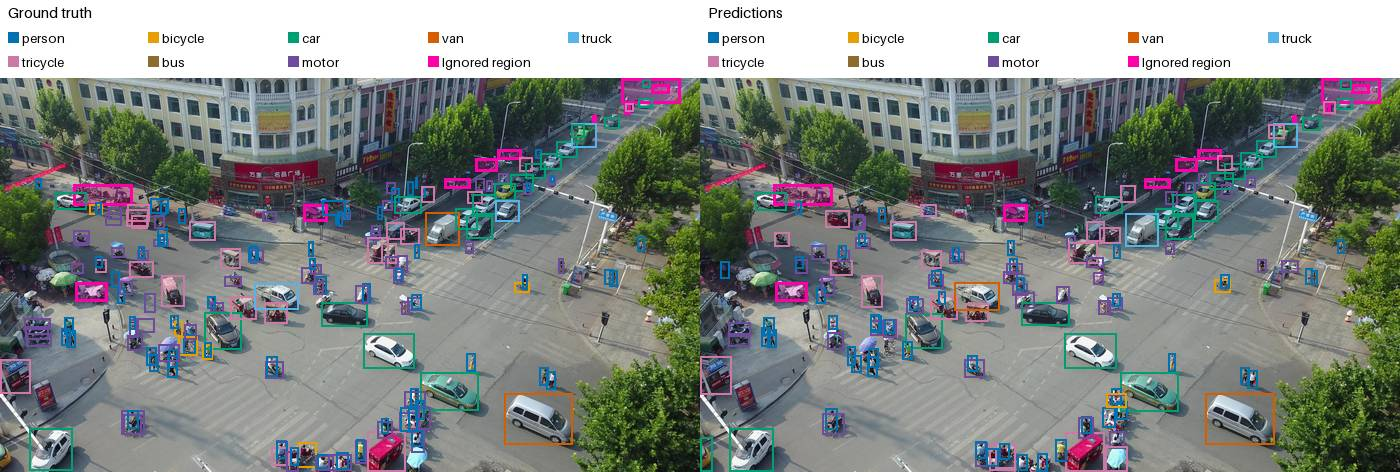

**Lowest recall among frames with at least 20 objects.** `val/uav0000268_05773_v/0000322`: 21 objects, 6 confident predictions.

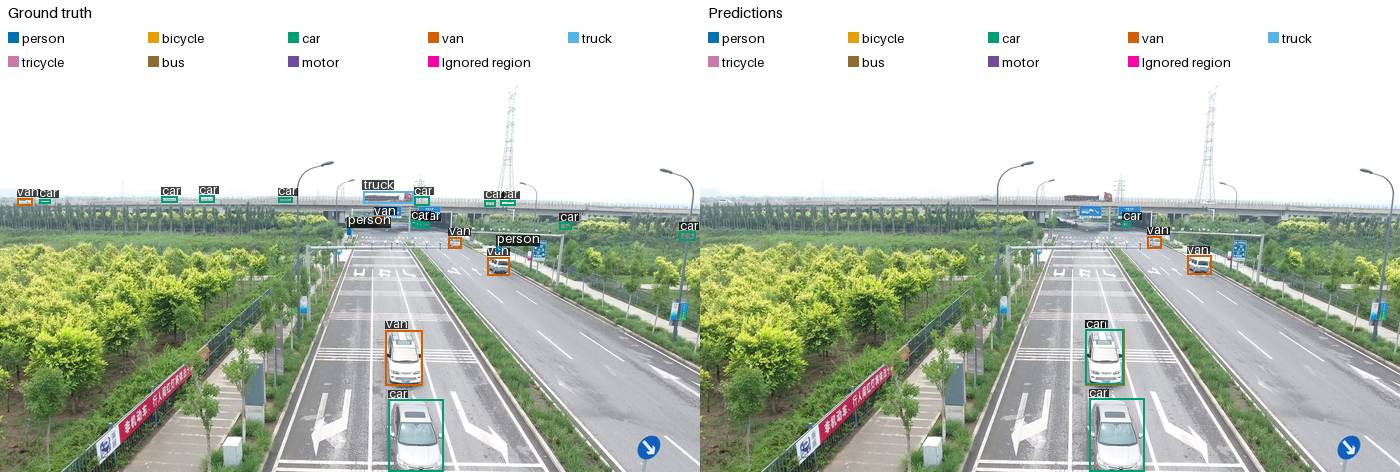

**Most ignored regions.** `train/uav0000278_00001_v/0000060`: 84 objects, 74 confident predictions.

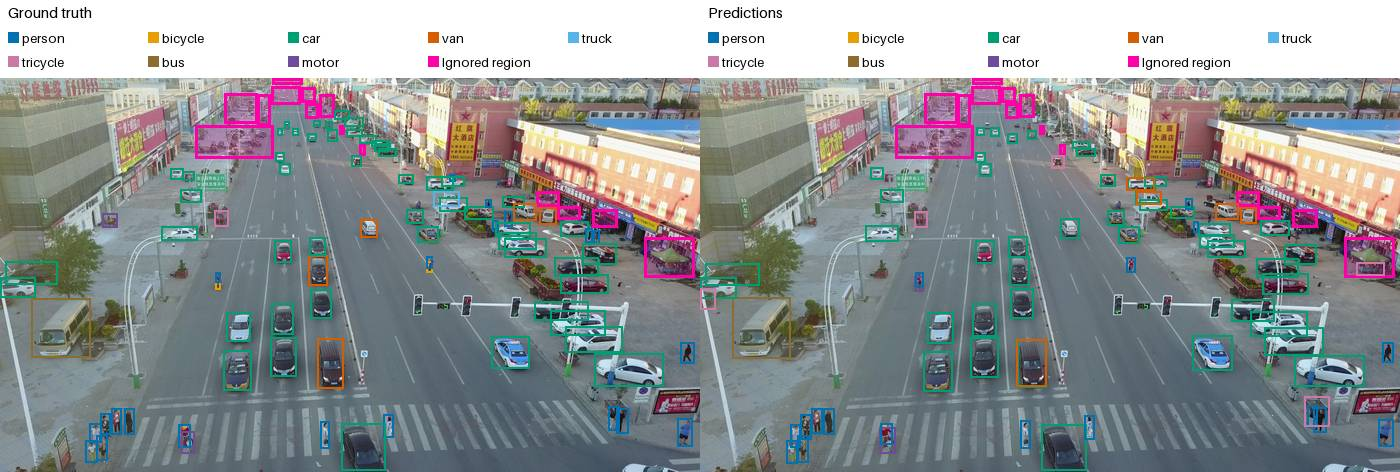

In [13]:
if SELECTED is not None:
    validation_objects = objects.filter(
        pl.col("image_key").is_in(validation_frames["image_key"].implode())
    )
    outcomes = classify_ground_truth_outcomes(
        selected_predictions, validation_frames, validation_objects, score_threshold=0.3
    ).with_columns(
        pl.when(pl.col("area") < 32**2)
        .then(pl.lit("Small"))
        .when(pl.col("area") < 96**2)
        .then(pl.lit("Medium"))
        .otherwise(pl.lit("Large"))
        .alias("Size"),
        pl.col("class_id").replace_strict(dict(enumerate(CLASS_NAMES))).alias("Class"),
    )
    for grouping in ("Size", "Class"):
        display(
            outcomes.group_by(grouping, "outcome")
            .len()
            .with_columns((pl.col("len") / pl.col("len").sum().over(grouping)).alias("fraction"))
            .pivot(on="outcome", index=grouping, values="fraction")
            .fill_null(0)
        )
    frame_recall = outcomes.group_by("image_key").agg(
        (pl.col("outcome") == "Detected").mean().alias("recall"), pl.len().alias("objects")
    )
    hard_frames = {
        "Densest validation frame": frame_recall.sort("objects", descending=True)["image_key"][0],
        "Lowest recall among frames with at least 20 objects": frame_recall.filter(
            pl.col("objects") >= 20
        ).sort("recall")["image_key"][0],
        "Most ignored regions": validation_frames.sort("ignore_count", descending=True)[
            "image_key"
        ][0],
    }
    keys = validation_frames["image_key"].to_list()
    for title, key in hard_frames.items():
        prediction = selected_predictions[keys.index(key)]
        keep = prediction["scores"] >= 0.3
        boxes = prediction["boxes"][keep]
        predicted = pl.DataFrame(
            {
                "class_id": prediction["classes"][keep],
                "x": boxes[:, 0],
                "y": boxes[:, 1],
                "width": boxes[:, 2] - boxes[:, 0],
                "height": boxes[:, 3] - boxes[:, 1],
            }
        )
        record = validation_frames.filter(pl.col("image_key") == key).row(0, named=True)
        display(
            Markdown(
                f"**{title}.** `{key}`: {record['target_count']} objects, {predicted.height} confident predictions."
            )
        )
        display_image(
            draw_prediction_pair(
                SOURCE_ROOT / record["relative_path"],
                validation_objects.filter(pl.col("image_key") == key),
                ignored.filter(pl.col("image_key") == key),
                predicted,
            )
        )

## 12. Test inference with the selected checkpoint

We predict every frame listed in `test_images.csv` with the selected checkpoint and
input size, using the same resize rule and inference settings as validation. Boxes are
mapped back to each frame's original pixel coordinates.

In [14]:
if SHOULD_EXPORT_SUBMISSION and SELECTED is not None and SELECTED_PATH is not None:
    model = YOLO(str(SELECTED_PATH))
    started = time.monotonic()
    test_predictions = predict_frames(
        model,
        test_frames.rename(
            {"file_name": "relative_path", "width": "image_width", "height": "image_height"}
        ),
        SOURCE_ROOT,
        SELECTED["image_size"],
        inference,
        device,
    )
    test_seconds = time.monotonic() - started
    display(
        Markdown(f"Test inference: {test_frames.height} frames in {test_seconds / 60:.1f} min.")
    )
else:
    test_predictions = None
    display(Markdown("Test export skipped: no selected checkpoint or export disabled."))

Test inference: 3811 frames in 1.2 min.

## 13. Competition submission export

Each row lists up to 500 boxes sorted by score as `class score x y width height`. It uses
class IDs 0 to 7 and top-left pixel coordinates, with empty strings for frames without
boxes. We write the CSV under a temporary name and rename it only after validation.
The metadata records the checkpoint, the input files and the validation result.

In [15]:
if test_predictions is not None and SELECTED is not None:
    submission = build_yolo_submission(test_predictions, test_frames)
    submission_name = f"{EXPERIMENT}_stride{SETTINGS['dataset']['frame_stride']}"
    submission_path = SUBMISSION_DIRECTORY / f"{submission_name}.csv"
    incoming = submission_path.with_suffix(".incoming")
    submission.write_csv(incoming)
    incoming.replace(submission_path)
    with (SOURCE_ROOT / "test_images.csv").open("rb") as stream:
        test_digest = hashlib.file_digest(stream, "sha256").hexdigest()
    with submission_path.open("rb") as stream:
        submission_digest = hashlib.file_digest(stream, "sha256").hexdigest()
    submission_metadata = {
        "experiment": EXPERIMENT,
        "batch_id": BATCH_ID,
        "checkpoint": SELECTED["checkpoint"],
        "checkpoint_sha256": SELECTED["sha256"],
        "image_size": SELECTED["image_size"],
        "inference": inference,
        "validation_map_500": SELECTED["validation"]["max_dets_500"]["map"],
        "validation_map_100": SELECTED["validation"]["max_dets_100"]["map"],
        "test_images_sha256": test_digest,
        "submission_sha256": submission_digest,
        "class_ids": "0-7 as in test labels and submissions",
        "coordinates": "original-image pixel top-left x, y, width, height",
        "official_sample_verified": (SOURCE_ROOT / "sample_submission.csv").is_file(),
    }
    write_json(SUBMISSION_DIRECTORY / f"{submission_name}.metadata.json", submission_metadata)
    display(pl.from_dicts([submission_metadata]).drop("inference"))

experiment,batch_id,checkpoint,checkpoint_sha256,image_size,validation_map_500,validation_map_100,test_images_sha256,submission_sha256,class_ids,coordinates,official_sample_verified
str,str,str,str,i64,f64,f64,str,str,str,str,bool
"""yolo11s_native_1280""","""yolo11s_native_1280_stride4_se…","""best""","""d821492586b4238ad9dea6bb1a9512…",1280,0.355827,0.355304,"""1c790b2c2436b62ff33905fddf08fc…","""059353d37c0ddb913c2249ceef692d…","""0-7 as in test labels and subm…","""original-image pixel top-left …",false


## 14. Submission checks

We check row order against `test_images.csv`, the number of detections per frame and
the class distribution. `build_yolo_submission` has already validated identifiers, class
IDs, score ranges, positive box sizes and the 500-detection cap.

In [16]:
if test_predictions is not None:
    written = pl.read_csv(submission_path, schema_overrides={"image_id": pl.String}).with_columns(
        pl.col("PredictionString").fill_null("")
    )
    counts = written.with_columns(
        pl.when(pl.col("PredictionString") == "")
        .then(0)
        .otherwise(pl.col("PredictionString").str.split(" ").list.len() // 6)
        .alias("detections")
    )
    if written["image_id"].to_list() != test_frames["image_id"].to_list():
        raise ValueError("Submission row order differs from test_images.csv.")
    classes = np.concatenate([prediction["classes"] for prediction in test_predictions])
    display(
        counts.join(test_frames.select("image_id", "width"), on="image_id")
        .group_by("width")
        .agg(
            pl.len().alias("Frames"),
            pl.col("detections").mean().alias("Mean detections"),
            pl.col("detections").max().alias("Max detections"),
            (pl.col("detections") == 0).sum().alias("Empty frames"),
        )
        .sort("width")
    )
    display(
        pl.DataFrame(
            {
                "Class": list(CLASS_NAMES),
                "Detections": np.bincount(classes, minlength=len(CLASS_NAMES)),
            }
        )
    )
    if drive_service is not None:
        MIRROR_DIRECTORY.mkdir(parents=True, exist_ok=True)
        for path in (
            submission_path,
            SUBMISSION_DIRECTORY / f"{submission_name}.metadata.json",
            RUN_PROJECT / "validation_selection.json",
            RUN_PROJECT / "dataset_manifest.json",
        ):
            shutil.copy2(path, MIRROR_DIRECTORY / path.name)
        publish_snapshot(MIRROR_DIRECTORY)
        sync_checkpoint_to_drive_api(drive_api, MIRROR_DIRECTORY, drive_folder)
    display(
        Markdown(
            f"Ready to upload: `{submission_path}` ({submission_path.stat().st_size / 1024**2:.1f} MiB)."
        )
    )

width,Frames,Mean detections,Max detections,Empty frames
i64,u32,f64,u32,u32
680,321,482.373832,500,0
960,279,499.72043,500,0
1344,441,442.1678,500,0
1360,1474,424.987788,500,0
1904,305,460.386885,500,0
1920,991,488.608476,500,0


Class,Detections
str,i64
"""person""",968340
"""bicycle""",24378
"""car""",465558
"""van""",8111
"""truck""",71829
"""tricycle""",45872
"""bus""",7141
"""motor""",153890


2026-11-08T15:36:30 [INFO] hm2.drive_api: Verified Drive API snapshot 1794152170626105829 in folder 1y09c6GqbLum511vYtF6pjH37pjuAEvOb


Ready to upload: `/kaggle/working/submissions/yolo11s_native_1280_stride4.csv` (59.9 MiB).

## 15. Results of all models

The earlier models were validated on the official split: 2,846 frames from seven clips,
after five epochs on every fifth training frame. The VisDrone-DET models use the clean
six-clip fold instead, because VisDrone-DET contains frames from six of the seven official
validation clips. Validation values from the two splits are therefore not comparable.
Kaggle Public is the only measurement shared by all models. Validation mAP is COCO
mAP@[.50:.95] at 100 detections per frame; unless stated otherwise it is the final epoch.
RetinaNet rows on all frames use the best-validation checkpoint that produced their CSV.

| Family | Model | Notebook | Validation split | Validation mAP | Kaggle Public |
| --- | --- | :---: | --- | ---: | ---: |
| One-stage anchor-based | RetinaNet, standard anchors, every fifth frame | 03 | official | 0.1528 | 0.16011 |
| One-stage anchor-based | RetinaNet, smaller anchors, every fifth frame | 03 | official | 0.1488 | 0.14203 |
| One-stage anchor-based | RetinaNet, standard anchors, all frames, epoch 1 | 03 | official | 0.1575 | 0.16827 |
| One-stage anchor-based | RetinaNet, smaller anchors, all frames, epoch 4 | 03 | official | 0.1588 | 0.15984 |
| Two-stage anchor-based | Faster R-CNN | 04 | official | 0.1747 | 0.20369 |
| Two-stage anchor-based | Faster R-CNN, epoch 1 (replication run) | 04 | official | 0.1945 | 0.18702 |
| Two-stage anchor-based | Faster R-CNN, photometric augmentation | 06 | official | 0.1789 | 0.19939 |
| Two-stage anchor-based | Faster R-CNN, input 800/1280 | 07 | official | 0.2086 | 0.19426 |
| Two-stage anchor-based | Faster R-CNN, repeat-factor sampling | 09 | official | 0.1822 | 0.19622 |
| One-stage anchor-free | YOLO11s, project training loop | 08 | official | 0.1550 | 0.14349 |
| Query-based | RT-DETRv2, 300 queries | 05 | official | 0.2456 | 0.25323 ¹ |
| Query-based | RT-DETRv2, NWD box loss | 05 | official | 0.2392 | 0.24090 |
| Query-based | RT-DETRv2, 500 queries | 05 | official | 0.2365 | 0.23331 |
| Query-based | RT-DETRv2, 300 denoising queries | 05 | official | 0.2367 | 0.24664 ¹ |
| One-stage anchor-free | VisDrone-DET YOLO11s without fine-tuning | 10 | clean fold | 0.3025 ² | 0.27998 ² |
| One-stage anchor-free | VisDrone-DET YOLO11s, one fine-tuning epoch (`best.pt`) | 10 | clean fold | 0.3553 | **0.34389** |
| One-stage anchor-free | VisDrone-DET YOLO11s after 11 epochs (`last.pt`) | 10 | clean fold | 0.3154 | not submitted |
| One-stage anchor-free | VisDrone-DET YOLO11s, low learning rate, test-time augmentation | 11 | clean fold | 0.3724 | 0.36181 |
| One-stage anchor-free | VisDrone-DET YOLO11s, all clips, multi-label NMS | 12 | grouped CV ³ | 0.3362 ³ | 0.34 |

¹ The first upload labelled as the 300-query model scored 0.24664, exactly the score of the
denoising export, so it was the denoising file. The corrected 300-query upload scored
0.25323 (Kaggle submission log of 8 November 2026).
² Person comes from the pedestrian channel on the clean fold, while the Public submission
merged the classes after inference.
³ Mean over four folds of 17 held-out videos that VisDrone-DET does not contain
([notebook 12](12_yolo11s_grouped_cv.ipynb)); not comparable with the clean fold.

The throughput check planned 30 epochs. Native validation peaked after the first epoch
and declined while the training loss kept falling, so early stopping ended the run after
epoch 11. The fine-tuned checkpoint improved both the clean fold and the Public score
over the initial checkpoint. Notebook 11 tests changes to this recipe, and notebook 12
re-tests them with cross-validation over videos.

## Limitations

- This is one seed and one recipe. Six validation clips and about 14 Public clips are
  small samples, so differences of about one AP point are within their noise.
- The initial weights come from an external VisDrone-DET model. We checked that no test
  frame appears in VisDrone-DET, and we cite the model and dataset. Its AGPL-3.0 and
  CC BY-NC-SA terms apply to this coursework use.
- The competition metric is a custom Kaggle metric. The data description says
  detections in ignored regions are not penalized, which our evaluator models with COCO
  crowd regions. The exact scorer is not published.
- Masking ignored regions in training means test crowds look unlike anything seen in
  training. Detections there are not penalized if the test crowds are marked as ignored.
- The epoch plan depends on measured throughput, so a different GPU type changes the
  number of epochs. Native training on CUDA is not bit-for-bit reproducible.